# ORF 455 HW3: code for Questions 3, 4 and 6

Data loading, analysis and figures for the three report questions. Run the cells in order.

Packages: `pip install pandas numpy matplotlib requests yfinance`

- **Q3** pulls live data, so the numbers depend on when you run it.
- **Q4** and **Q6** use historical data, so they should reproduce the report.

In [1]:
%pip install yfinance


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import io, zipfile, datetime as dt
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

COLORS = ['#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4','#008300','#6250d6','#e34948']
GRAY = '#8a8985'
plt.rcParams.update({'font.size': 8, 'axes.titlesize': 9, 'legend.fontsize': 7,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'legend.frameon': False,
                     'figure.dpi': 150, 'savefig.bbox': 'tight'})
HEADERS = {'User-Agent': 'Mozilla/5.0 (ORF455 homework script)'}

## Question 3: PJM and ERCOT current conditions

This section uses the snapshot pulled on **Mon Nov 2, 2026, 8:19 to 8:34 pm EST**, saved in the `q3_data/` folder. That way it runs with no API key and matches the report. The code for pulling fresh live data is in the appendix at the end.

| File | Source |
| --- | --- |
| `ercot_fuel_hourly.csv` | ERCOT fuel-mix dashboard, hourly averages, Nov 2 |
| `ercot_demand.csv` | ERCOT system-wide demand vs current and day-ahead forecast |
| `ercot_ws.csv` | ERCOT wind and solar actual vs STWPF/STPPF and day-ahead forecasts |
| `ercot_rt.csv`, `ercot_da.csv` | ERCOT RT (15-min) and DA settlement point prices by hub/zone |
| `pjm_fuel_hourly.csv` | PJM Data Miner 2, generation by fuel, 10:00 to 19:00 EPT |
| `pjm_load.csv` | PJM Data Viewer: actual (5-min avg), latest, original and day-ahead load |
| `pjm_lmp.csv` | PJM Data Viewer: RT and DA LMPs for ComEd, Dominion, RTO, Western Hub |

In [3]:
D = 'q3_data/'
# ERCOT fuel mix at the latest interval (7:10 pm CST), from the dashboard
latest = pd.Series({'Natural Gas': 26678, 'Wind': 21726, 'Coal & Lignite': 7142,
                    'Storage (discharging)': 4566, 'Nuclear': 3834, 'Hydro': 63, 'Solar': 1})
print('ERCOT total gen', latest.sum(), 'MW')
print((100 * latest / latest.sum()).round(1).to_string())
print('ERCOT renewable share now: %.1f%%' % (100 * latest[['Wind', 'Solar', 'Hydro']].sum() / latest.sum()))
ef = pd.read_csv(D + 'ercot_fuel_hourly.csv').drop(columns='hour').clip(lower=0).sum()
print('ERCOT renewable share midnight-7pm: %.1f%%' % (100 * ef[['Wind', 'Solar', 'Hydro']].sum() / ef.sum()))

pf = pd.read_csv(D + 'pjm_fuel_hourly.csv')
last = pf.iloc[-1].drop('hour_ept').sort_values(ascending=False)
print('\nPJM total gen', last.sum(), 'MW')
print((100 * last / last.sum()).round(1).to_string())
REN = ['Hydro', 'Wind', 'Solar', 'OtherRenewables']
print('PJM renewable share now: %.1f%%' % (100 * last[REN].sum() / last.sum()))
day = pf.drop(columns='hour_ept').sum()
print('PJM renewable share 10am-7pm: %.1f%%' % (100 * day[REN].sum() / day.sum()))

ERCOT total gen 64010 MW
Natural Gas              41.7
Wind                     33.9
Coal & Lignite           11.2
Storage (discharging)     7.1
Nuclear                   6.0
Hydro                     0.1
Solar                     0.0
ERCOT renewable share now: 34.0%
ERCOT renewable share midnight-7pm: 50.1%

PJM total gen 95773 MW
Gas                39.1
Nuclear            30.6
Coal               14.5
Wind                6.7
Hydro               4.4
MultipleFuels       2.8
Oil                 1.1
OtherRenewables     0.7
Storage             0.2
Solar               0.1
PJM renewable share now: 11.9%
PJM renewable share 10am-7pm: 11.5%


In [4]:
def err_stats(fcst, act):
    m = act.notna() & fcst.notna()
    e = fcst[m] - act[m]
    return pd.Series({'MAE': e.abs().mean(), 'MAPE %': 100 * (e.abs() / act[m]).mean(), 'bias': e.mean()}).round(2)

dem = pd.read_csv(D + 'ercot_demand.csv')
wsd = pd.read_csv(D + 'ercot_ws.csv')
print('ERCOT current load fcst:', err_stats(dem.current_fcst, dem.actual).to_dict())
print('ERCOT day-ahead load fcst:', err_stats(dem.dayahead_fcst, dem.actual).to_dict())
print('ERCOT wind STWPF:', err_stats(wsd.wind_stwpf, wsd.wind_act).to_dict())
d = wsd[wsd.solar_act > 100]
print('ERCOT solar STPPF (daylight):', err_stats(d.solar_stppf, d.solar_act).to_dict())

pl = pd.read_csv(D + 'pjm_load.csv')
pt = pl[(pl.hourEST >= '11-02T00') & (pl.hourEST < '11-02T20')]   # full hours on Nov 2 before access
for c in ['Forecast', 'Original', 'DayAhead']:
    print('PJM', c, err_stats(pt[c], pt.InstAvg).to_dict())

ERCOT current load fcst: {'MAE': 379.42, 'MAPE %': 0.65, 'bias': -61.32}
ERCOT day-ahead load fcst: {'MAE': 471.05, 'MAPE %': 0.76, 'bias': -339.37}
ERCOT wind STWPF: {'MAE': 3302.89, 'MAPE %': 15.86, 'bias': 3302.89}
ERCOT solar STPPF (daylight): {'MAE': 1657.64, 'MAPE %': 10.39, 'bias': 1521.45}
PJM Forecast {'MAE': 72.4, 'MAPE %': 0.09, 'bias': 45.6}
PJM Original {'MAE': 1307.3, 'MAPE %': 1.48, 'bias': 1307.3}
PJM DayAhead {'MAE': 4121.7, 'MAPE %': 4.77, 'bias': -4121.7}


In [5]:
rt = pd.read_csv(D + 'ercot_rt.csv'); da = pd.read_csv(D + 'ercot_da.csv')
cols = [c for c in rt.columns if c not in ('ie', 'hbBusAvg', 'hbHubAvg')]
print('ERCOT RT average by hub/zone, low to high:'); print(rt[cols].mean().round(1).sort_values().to_string())
print('ERCOT RT max:'); print(rt[cols].max().round(1).sort_values().tail(3).to_string())
print('ERCOT DA average:'); print(da[cols].mean().round(1).sort_values().to_string())

lm = pd.read_csv(D + 'pjm_lmp.csv'); x = lm[lm.hourEST >= '11-02T00']
print('\nPJM RT avg Nov 2:', x[['COMED', 'DOM', 'RTO', 'WHUB']].mean().round(1).to_dict())
print('PJM DA avg Nov 2:', x[['COMED_DA', 'DOM_DA', 'RTO_DA', 'WHUB_DA']].mean().round(1).to_dict())

ERCOT RT average by hub/zone, low to high:
hbPan         0.5
hbWest        3.1
lzWest        4.7
hbNorth      15.5
lzRaybn      16.9
lzNorth      19.1
lzCps        24.0
hbSouth      24.2
lzLcra       26.6
lzSouth      26.7
lzAen        28.1
hbHouston    56.9
lzHouston    79.7
ERCOT RT max:
lzSouth      163.5
hbHouston    276.2
lzHouston    391.2
ERCOT DA average:
hbPan         7.2
hbWest       14.5
lzWest       17.9
lzRaybn      24.6
hbNorth      24.8
lzNorth      26.2
hbSouth      31.2
lzCps        31.3
lzSouth      33.0
lzLcra       33.2
lzAen        34.2
hbHouston    37.9
lzHouston    40.3

PJM RT avg Nov 2: {'COMED': 20.8, 'DOM': 116.2, 'RTO': 71.5, 'WHUB': 90.2}
PJM DA avg Nov 2: {'COMED_DA': 26.1, 'DOM_DA': 75.0, 'RTO_DA': 53.0, 'WHUB_DA': 63.4}


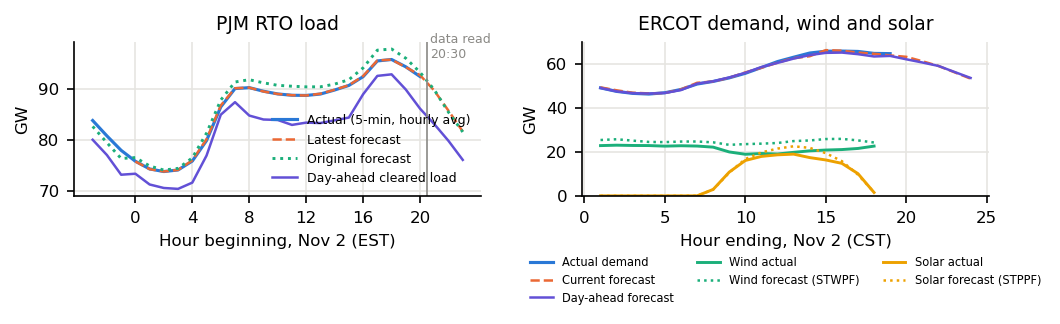

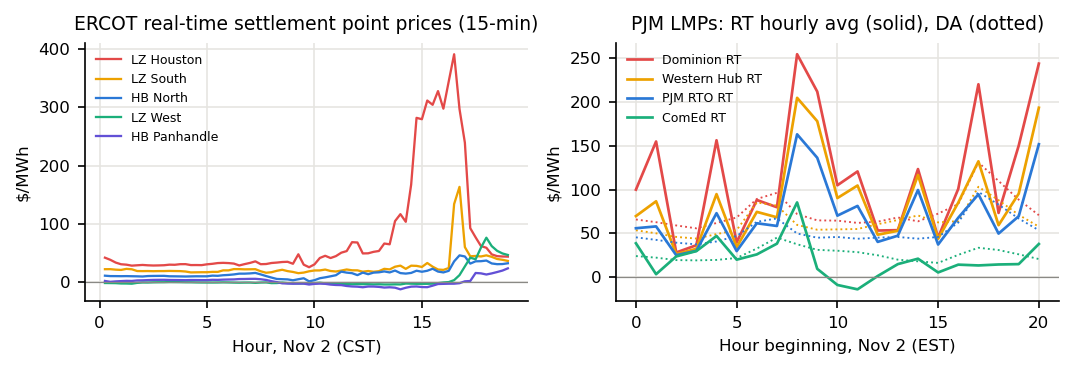

In [6]:
# --- Figure 1: load vs forecasts ---
L = pl.copy(); L['h'] = range(-3, len(L) - 3)
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.5))
a = ax[0]
a.plot(L.h, L.InstAvg / 1e3, color=COLORS[0], label='Actual (5-min, hourly avg)')
a.plot(L.h, L.Forecast / 1e3, color=COLORS[1], ls='--', lw=1.2, label='Latest forecast')
a.plot(L.h, L.Original / 1e3, color=COLORS[2], ls=':', lw=1.4, label='Original forecast')
a.plot(L.h, L.DayAhead / 1e3, color=COLORS[6], lw=1.2, label='Day-ahead cleared load')
a.axvline(20.5, color=GRAY, lw=0.8); a.text(20.7, 96, 'data read\n20:30', fontsize=6, color=GRAY)
a.set_xticks([0, 4, 8, 12, 16, 20]); a.set(xlabel='Hour beginning, Nov 2 (EST)', ylabel='GW', title='PJM RTO load')
a.legend(loc='lower right', fontsize=6)
a = ax[1]
a.plot(dem.he, dem.actual / 1e3, color=COLORS[0], label='Actual demand')
a.plot(dem.he, dem.current_fcst / 1e3, color=COLORS[1], ls='--', lw=1.2, label='Current forecast')
a.plot(dem.he, dem.dayahead_fcst / 1e3, color=COLORS[6], lw=1.2, label='Day-ahead forecast')
a.plot(wsd.he, wsd.wind_act / 1e3, color=COLORS[2], lw=1.4, label='Wind actual')
a.plot(wsd.he, wsd.wind_stwpf / 1e3, color=COLORS[2], ls=':', lw=1.2, label='Wind forecast (STWPF)')
a.plot(wsd.he, wsd.solar_act / 1e3, color=COLORS[3], lw=1.4, label='Solar actual')
a.plot(wsd.he, wsd.solar_stppf / 1e3, color=COLORS[3], ls=':', lw=1.2, label='Solar forecast (STPPF)')
a.set(xlabel='Hour ending, Nov 2 (CST)', ylabel='GW', title='ERCOT demand, wind and solar', ylim=(0, 70))
a.legend(loc='upper center', fontsize=5.5, ncol=3, bbox_to_anchor=(0.5, -0.33))
plt.tight_layout(); plt.savefig('q3_demand.png')

# --- Figure 2: prices ---
t = [int(s[:2]) + int(s[3:]) / 60 for s in rt.ie]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.5))
for c, col, lab in [('lzHouston', COLORS[7], 'LZ Houston'), ('lzSouth', COLORS[3], 'LZ South'), ('hbNorth', COLORS[0], 'HB North'),
                    ('lzWest', COLORS[2], 'LZ West'), ('hbPan', COLORS[6], 'HB Panhandle')]:
    ax[0].plot(t, rt[c], color=col, lw=1.1, label=lab)
ax[0].axhline(0, color=GRAY, lw=0.6)
ax[0].set(xlabel='Hour, Nov 2 (CST)', ylabel='$/MWh', title='ERCOT real-time settlement point prices (15-min)'); ax[0].legend(fontsize=6, loc='upper left')
h = [int(s[-2:]) for s in x.hourEST]
for c, col, lab in [('DOM', COLORS[7], 'Dominion'), ('WHUB', COLORS[3], 'Western Hub'), ('RTO', COLORS[0], 'PJM RTO'), ('COMED', COLORS[2], 'ComEd')]:
    ax[1].plot(h, x[c], color=col, lw=1.3, label=lab + ' RT'); ax[1].plot(h, x[c + '_DA'], color=col, lw=0.9, ls=':')
ax[1].axhline(0, color=GRAY, lw=0.6)
ax[1].set(xlabel='Hour beginning, Nov 2 (EST)', ylabel='$/MWh', title='PJM LMPs: RT hourly avg (solid), DA (dotted)'); ax[1].legend(fontsize=6, loc='upper left')
plt.tight_layout(); plt.savefig('q3_prices.png')

## Question 4: Commodity financialization and Bitcoin

Daily closes from Yahoo Finance via `yfinance`. The steps:

1. Resample to Friday closes and take weekly log returns.
2. Compute rolling 52-week correlations with the S&P 500.
3. Compute the average pairwise correlation among the eight commodities.
4. Summarize by period.

In [7]:
import yfinance as yf

TICKERS = {'SPX': '^GSPC', 'NDX': '^IXIC', 'DXY': 'DX-Y.NYB', 'BTC': 'BTC-USD',
           'WTI': 'CL=F', 'NG': 'NG=F', 'GOLD': 'GC=F', 'SILVER': 'SI=F',
           'COPPER': 'HG=F', 'CORN': 'ZC=F', 'WHEAT': 'ZW=F', 'SOY': 'ZS=F'}
COMS = ['WTI', 'NG', 'GOLD', 'SILVER', 'COPPER', 'CORN', 'WHEAT', 'SOY']

raw = yf.download(list(TICKERS.values()), start='2000-01-01', end='2026-10-24', auto_adjust=True, progress=False)['Close']
px = raw.rename(columns={v: k for k, v in TICKERS.items()})
px = px.where(px > 0)


1 Failed download:
['NG=F']: OperationalError('database is locked')


In [8]:
def weekly_returns(px):
    wk = px.resample('W-FRI').last()       # last close on or before each Friday
    return np.log(wk / wk.shift(1))

def rolling_avg_pairwise(R, cols, window=52):
    pairs = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:]]
    rc = pd.concat([R[a].rolling(window, min_periods=20).corr(R[b]) for a, b in pairs], axis=1)
    return rc.mean(axis=1)

def avg_pairwise(R, cols):
    c = R[cols].corr()
    return c.values[np.triu_indices(len(cols), 1)].mean()

R = weekly_returns(px)
R['BASKET'] = R[COMS].mean(axis=1, skipna=True).where(R[COMS].notna().sum(axis=1) >= 6)

W = 52
roll = pd.DataFrame({f'{c}_spx': R[c].rolling(W, min_periods=20).corr(R.SPX) for c in COMS + ['BASKET']})
roll['avgpair'] = rolling_avg_pairwise(R, COMS, W)
roll['BASKET_dxy'] = R.BASKET.rolling(W, min_periods=20).corr(R.DXY)
for c in ['SPX', 'NDX', 'GOLD', 'DXY']:
    roll[f'BTC_{c.lower()}'] = R.BTC.rolling(W, min_periods=20).corr(R[c])

In [9]:
PERIODS = [('2000-08-25', '2003-12-31', '2000-2003 (before indexing)'),
           ('2004-01-01', '2008-06-30', '2004-mid 2008 (index boom)'),
           ('2008-07-01', '2009-12-31', 'Mid 2008-2009 (financial crisis)'),
           ('2010-01-01', '2014-06-30', '2010-mid 2014 (QE era)'),
           ('2014-07-01', '2019-12-31', 'Mid 2014-2019 (shale glut)'),
           ('2020-01-01', '2021-12-31', '2020-2021 (COVID)'),
           ('2022-01-01', '2023-12-31', '2022-2023 (Ukraine, rate hikes)'),
           ('2024-01-01', '2026-10-24', '2024-Oct 2026')]
rows = []
for a, b, name in PERIODS:
    x = R.loc[a:b]
    row = {c: x[c].corr(x.SPX) for c in ['BASKET', 'WTI', 'COPPER', 'GOLD', 'CORN']}
    row['avg pairwise'] = avg_pairwise(x, COMS)
    rows.append(pd.Series(row, name=name))
table1 = pd.DataFrame(rows).round(2)
table1

BTC_PERIODS = [('2014-09-19', '2017-12-31', 'Sep 2014-2017'), ('2018-01-01', '2019-12-31', '2018-2019'),
               ('2020-01-01', '2021-12-31', '2020-2021'), ('2022-01-01', '2023-12-31', '2022-2023'),
               ('2024-01-01', '2026-10-24', '2024-Oct 2026')]
rows = []
for a, b, name in BTC_PERIODS:
    x = R.loc[a:b]
    row = {c: x.BTC.corr(x[c]) for c in ['SPX', 'NDX', 'GOLD', 'DXY', 'BASKET']}
    row['BTC vol'] = x.BTC.std() * np.sqrt(52)
    row['Gold vol'] = x.GOLD.std() * np.sqrt(52)
    rows.append(pd.Series(row, name=name))
table2 = pd.DataFrame(rows).round(2)
print(table1); print(table2)

                                  BASKET   WTI  COPPER  GOLD  CORN  \
2000-2003 (before indexing)         0.09 -0.05    0.33 -0.09  0.07   
2004-mid 2008 (index boom)          0.03 -0.13    0.15 -0.02  0.09   
Mid 2008-2009 (financial crisis)    0.53  0.42    0.61 -0.02  0.41   
2010-mid 2014 (QE era)              0.46  0.52    0.57  0.19  0.14   
Mid 2014-2019 (shale glut)          0.25  0.34    0.31 -0.16  0.04   
2020-2021 (COVID)                   0.57  0.41    0.50  0.42  0.21   
2022-2023 (Ukraine, rate hikes)     0.13  0.08    0.31  0.19 -0.07   
2024-Oct 2026                       0.29 -0.09    0.37  0.14  0.09   

                                  avg pairwise  
2000-2003 (before indexing)                NaN  
2004-mid 2008 (index boom)                 NaN  
Mid 2008-2009 (financial crisis)           NaN  
2010-mid 2014 (QE era)                     NaN  
Mid 2014-2019 (shale glut)                 NaN  
2020-2021 (COVID)                          NaN  
2022-2023 (Ukraine, rate h

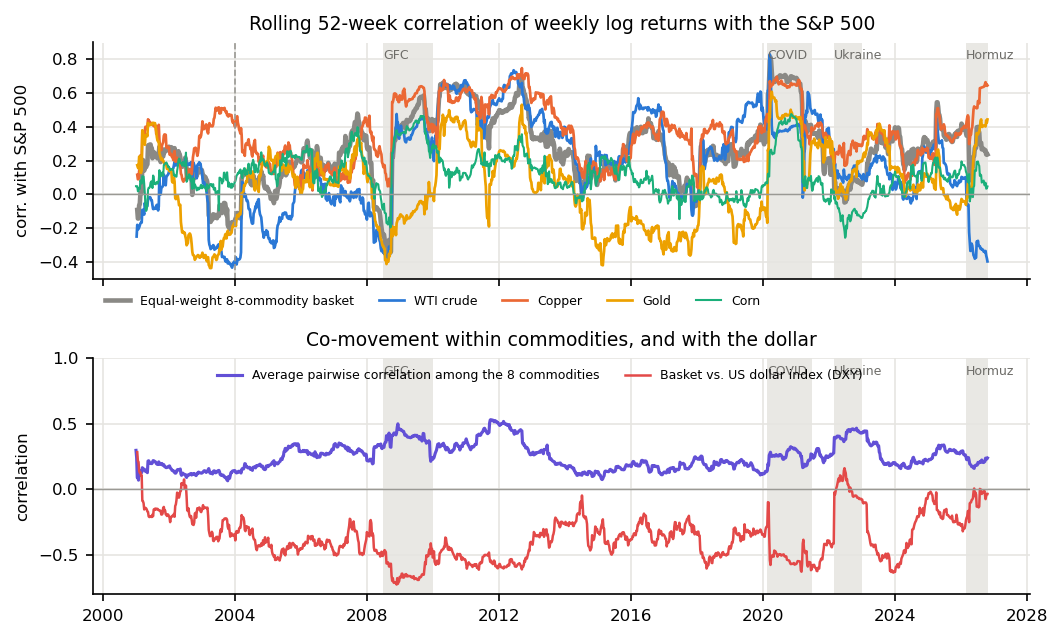

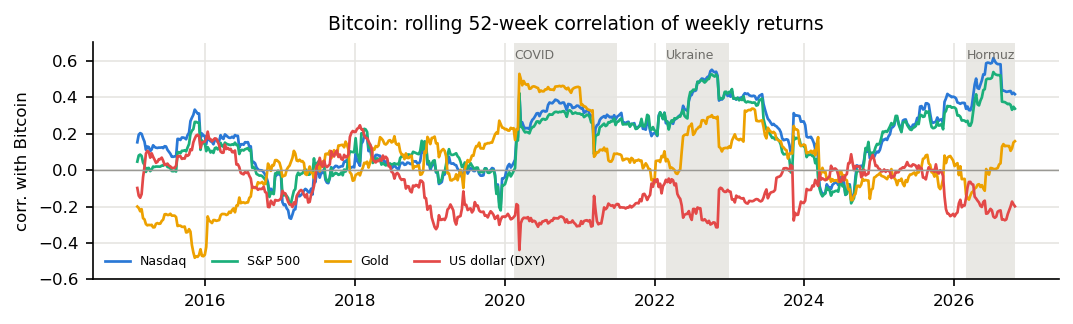

In [10]:
REGIMES = [('2008-07-01', '2009-12-31', 'GFC'), ('2020-02-15', '2021-06-30', 'COVID'),
           ('2022-02-24', '2022-12-31', 'Ukraine'), ('2026-03-01', '2026-10-24', 'Hormuz')]
def shade(a, regimes=REGIMES):
    for s, e, n in regimes:
        a.axvspan(pd.Timestamp(s), pd.Timestamp(e), color='#e9e8e4', lw=0, zorder=0)
        a.text(pd.Timestamp(s), 0.93, n, transform=a.get_xaxis_transform(), fontsize=6, color='#6d6c68')

r = roll.loc['2001':]
fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.3), sharex=True)
a = ax[0]; shade(a)
for c, col, lab, lw in [('BASKET_spx', GRAY, 'Equal-weight 8-commodity basket', 2.2), ('WTI_spx', COLORS[0], 'WTI crude', 1.3),
                        ('COPPER_spx', COLORS[1], 'Copper', 1.3), ('GOLD_spx', COLORS[3], 'Gold', 1.3), ('CORN_spx', COLORS[2], 'Corn', 1.0)]:
    a.plot(r.index, r[c], color=col, lw=lw, label=lab)
a.axhline(0, color='#9a9994', lw=0.7)
a.axvline(pd.Timestamp('2004-01-01'), color='#9a9994', ls='--', lw=0.8)
a.set(ylabel='corr. with S&P 500', title='Rolling 52-week correlation of weekly log returns with the S&P 500', ylim=(-0.5, 0.9))
a.legend(ncol=5, fontsize=6, loc='upper left', bbox_to_anchor=(0, -0.02))
a = ax[1]; shade(a)
a.plot(r.index, r.avgpair, color=COLORS[6], label='Average pairwise correlation among the 8 commodities')
a.plot(r.index, r.BASKET_dxy, color=COLORS[7], lw=1.2, label='Basket vs. US dollar index (DXY)')
a.axhline(0, color='#9a9994', lw=0.7)
a.set(ylabel='correlation', title='Co-movement within commodities, and with the dollar', ylim=(-0.8, 1.0))
a.legend(fontsize=6, loc='upper left', ncol=2, bbox_to_anchor=(0.12, 1.0))
plt.tight_layout(); plt.savefig('q4_corr.png')

b = roll.loc['2015':]
fig, a = plt.subplots(figsize=(7.2, 2.2)); shade(a, REGIMES[1:])
for c, col, lab in [('BTC_ndx', COLORS[0], 'Nasdaq'), ('BTC_spx', COLORS[2], 'S&P 500'),
                    ('BTC_gold', COLORS[3], 'Gold'), ('BTC_dxy', COLORS[7], 'US dollar (DXY)')]:
    a.plot(b.index, b[c], color=col, lw=1.3, label=lab)
a.axhline(0, color='#9a9994', lw=0.7)
a.set(ylabel='corr. with Bitcoin', title='Bitcoin: rolling 52-week correlation of weekly returns', ylim=(-0.6, 0.7))
a.legend(ncol=4, fontsize=6, loc='lower left')
plt.tight_layout(); plt.savefig('q4_btc.png')

## Question 6: NYISO during the July 2026 heatwave

Everything comes from NYISO's public monthly zip archives on mis.nyiso.com.

- 5-minute timestamps are interval-ending, so they are shifted back one interval before averaging to hours.
- The day-ahead load forecast for day D is taken from the forecast file issued on day D-1.

In [11]:
BASE = 'https://mis.nyiso.com/public/csv'
_zips = {}

def nyiso_day(kind, suffix, day):
    """Return one day's CSV from NYISO's monthly zip archive, e.g. nyiso_day('damlbmp', '_zone', '20260702')."""
    month = day[:6] + '01'
    key = (kind, suffix, month)
    if key not in _zips:
        url = f'{BASE}/{kind}/{month}{kind}{suffix}_csv.zip'
        r = requests.get(url, headers=HEADERS, timeout=120); r.raise_for_status()
        _zips[key] = zipfile.ZipFile(io.BytesIO(r.content))
    name = f'{day}{kind}{suffix}.csv'
    return pd.read_csv(_zips[key].open(name))

def hour_of(ts, interval_ending=False):
    t = pd.to_datetime(ts)
    if interval_ending:
        t = t - pd.Timedelta(minutes=1)
    return t.dt.floor('h')

MILD = ['20260622', '20260623', '20260624', '20260625', '20260626']
HEAT = ['20260629', '20260630', '20260701', '20260702', '20260703']
ZONES = {'N.Y.C.': 'NYC', 'LONGIL': 'LONGIL', 'HUD VL': 'HUDVL', 'CAPITL': 'CAPITL', 'WEST': 'WEST', 'NORTH': 'NORTH'}

In [12]:
def build_day(day):
    out = {}
    # actual load: sum zones per 5-min timestamp, then average within the hour
    pal = nyiso_day('pal', '', day)
    tot = pal.groupby('Time Stamp').Load.sum()
    out['Load'] = tot.groupby(hour_of(pd.Series(tot.index), False).values).mean()
    # day-ahead load forecast issued the previous day
    prev = (pd.Timestamp(day) - pd.Timedelta(days=1)).strftime('%Y%m%d')
    lf = nyiso_day('isolf', '', prev)
    lf['t'] = pd.to_datetime(lf['Time Stamp'])
    out['LF_DA'] = lf.set_index('t')['NYISO']
    # day-ahead zonal LBMP (hourly)
    dam = nyiso_day('damlbmp', '_zone', day)
    dam['t'] = pd.to_datetime(dam['Time Stamp'])
    for z, short in ZONES.items():
        out['DA_' + short] = dam[dam.Name == z].set_index('t')['LBMP ($/MWHr)']
    out['DAcong_NYC'] = dam[dam.Name == 'N.Y.C.'].set_index('t')['Marginal Cost Congestion ($/MWHr)']
    # real-time zonal LBMP (5-min, interval ending) -> hourly average
    rt = nyiso_day('realtime', '_zone', day)
    rt['t'] = hour_of(rt['Time Stamp'], True)
    for z, short in ZONES.items():
        out['RT_' + short] = rt[rt.Name == z].groupby('t')['LBMP ($/MWHr)'].mean()
    # real-time fuel mix (5-min, interval ending) -> hourly average by fuel
    fmx = nyiso_day('rtfuelmix', '', day)
    fmx['t'] = hour_of(fmx['Time Stamp'], True)
    fuel = fmx.groupby(['t', 'Fuel Category'])['Gen MW'].mean().unstack()
    df = pd.DataFrame(out).join(fuel.add_prefix('F_'))
    return df[df.index.strftime('%Y%m%d') == day]

h = pd.concat([build_day(d) for d in MILD + HEAT])
h['period'] = np.where(h.index < '2026-06-27', 'Mild (Jun 22-26)', 'Heat (Jun 29-Jul 3)')
FUELS = [c for c in h.columns if c.startswith('F_')]
h['Gen'] = h[FUELS].sum(axis=1)
h['NetImp'] = h.Load - h.Gen                  # net imports = load minus internal generation
h['fcst_err'] = h.LF_DA - h.Load
for z in ZONES.values():
    h['spr_' + z] = h['RT_' + z] - h['DA_' + z]

In [13]:
def summarize(x):
    gen = x[FUELS].sum()
    s = {'avg load': x.Load.mean(), 'peak load': x.Load.max(),
         'DA fcst MAPE %': 100 * (x.fcst_err.abs() / x.Load).mean(),
         'DA NYC avg': x.DA_NYC.mean(), 'DA WEST avg': x.DA_WEST.mean(), 'DA NYC max': x.DA_NYC.max(),
         'RT NYC avg': x.RT_NYC.mean(), 'RT WEST avg': x.RT_WEST.mean(),
         'RT NYC max': x.RT_NYC.max(), 'RT LI max': x.RT_LONGIL.max(),
         'NYC-WEST DA spread': (x.DA_NYC - x.DA_WEST).mean(),
         'oil avg': x['F_Other Fossil Fuels'].mean(), 'oil max': x['F_Other Fossil Fuels'].max(),
         'net imports avg': x.NetImp.mean(),
         'RT-DA NYC mean': x.spr_NYC.mean(), 'RT-DA NYC sd': x.spr_NYC.std(),
         'hours RT>DA+100': (x.spr_NYC > 100).sum(), 'hours RT<DA-50': (x.spr_NYC < -50).sum()}
    s.update({'share ' + c[2:]: 100 * gen[c] / gen.sum() for c in FUELS})
    return pd.Series(s)

table4 = h.groupby('period', sort=False).apply(summarize).T.round(1)
table4

/var/folders/t9/zwqm_8x90l7_f6mdc9s_hhlh0000gn/T/ipykernel_8215/2164789229.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table4 = h.groupby('period', sort=False).apply(summarize).T.round(1)


period,Mild (Jun 22-26),Heat (Jun 29-Jul 3)
avg load,17602.0,23436.0
peak load,21490.1,31073.0
DA fcst MAPE %,2.9,2.5
DA NYC avg,49.9,150.8
DA WEST avg,39.7,112.9
DA NYC max,75.4,847.8
RT NYC avg,44.8,197.9
RT WEST avg,36.1,99.3
RT NYC max,106.7,1683.7
RT LI max,110.5,2285.1


In [14]:
# --- Bid stacks from the day-ahead generator offers ---
def gen_bids(month):
    url = f'{BASE}/biddata/{month}biddata_genbids_csv.zip'
    r = requests.get(url, headers=HEADERS, timeout=300); r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    df = pd.read_csv(z.open(z.namelist()[0]), skipinitialspace=True, low_memory=False)
    df.columns = df.columns.str.strip()
    return df

def offer_stack(bids, when):
    """Supply curve for one hour: every incremental MW block at its offer price, sorted by price."""
    b = bids[(bids['Date Time'].str.strip() == when) & (bids['Market'].str.strip() == 'DAM')]
    blocks = []
    for _, row in b.iterrows():
        prev = 0.0
        for k in range(1, 13):
            mw, p = pd.to_numeric(row.get(f'Dispatch MW{k}'), errors='coerce'), pd.to_numeric(row.get(f'Dispatch $/MW{k}'), errors='coerce')
            if pd.isna(mw) or pd.isna(p):
                continue
            if mw > prev:
                blocks.append((p, mw - prev))
            prev = max(prev, mw)
    s = pd.DataFrame(blocks, columns=['price', 'mw']).sort_values('price')
    s['cum_mw'] = s.mw.cumsum()
    return s, len(b)

def clearing_price(stack, demand):
    i = np.searchsorted(stack.cum_mw.values, demand)
    return stack.price.values[min(i, len(stack) - 1)]

bids = {'202606': gen_bids('20260601'), '202607': gen_bids('20260701')}
HOURS = {'23JUN2026:08:00:00': ('202606', '2026-06-23 08:00', 'Jun 23 08:00 (mild)', COLORS[2]),
         '23JUN2026:18:00:00': ('202606', '2026-06-23 18:00', 'Jun 23 18:00 (mild)', COLORS[0]),
         '02JUL2026:08:00:00': ('202607', '2026-07-02 08:00', 'Jul 2 08:00 (heat)', COLORS[3]),
         '02JUL2026:18:00:00': ('202607', '2026-07-02 18:00', 'Jul 2 18:00 (heat)', COLORS[7])}

stacks, res = {}, []
for when, (m, t, lab, col) in HOURS.items():
    s, n = offer_stack(bids[m], when)
    r = h.loc[t]
    demand = r.LF_DA - r.NetImp                 # internal demand = DA forecast minus net imports
    stacks[when] = (s, demand, lab, col)
    da = [r['DA_' + z] for z in ZONES.values()]
    res.append({'hour': lab, 'bids': n, 'offered MW': s.mw.sum(), 'internal demand': demand,
                'spare MW': s.mw.sum() - demand, 'estimate': clearing_price(s, demand),
                'with 2.6 GW reserves': clearing_price(s, demand + 2620),
                'with 3.5 GW reserves': clearing_price(s, demand + 3500),
                'actual DA min': min(da), 'actual DA max': max(da)})
table5 = pd.DataFrame(res).round(1)
table5

,hour,bids,offered MW,internal demand,spare MW,estimate,with 2.6 GW reserves,with 3.5 GW reserves,actual DA min,actual DA max
0,Jun 23 08:00 (mild),270,32006.4,13401.2,18605.2,43.1,50.6,52.1,37.3,46.1
1,Jun 23 18:00 (mild),287,33673.1,18110.5,15562.6,50.2,56.4,57.9,52.6,70.8
2,Jul 2 08:00 (heat),271,31194.5,20132.5,11062.0,69.7,80.0,95.7,63.5,70.6
3,Jul 2 18:00 (heat),287,32908.9,28187.8,4721.1,161.8,326.1,407.6,563.8,808.2


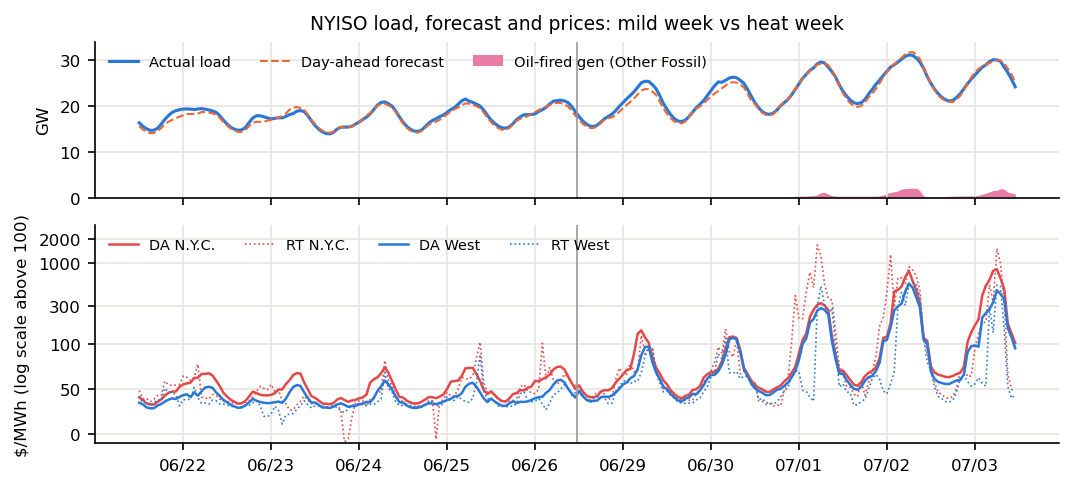

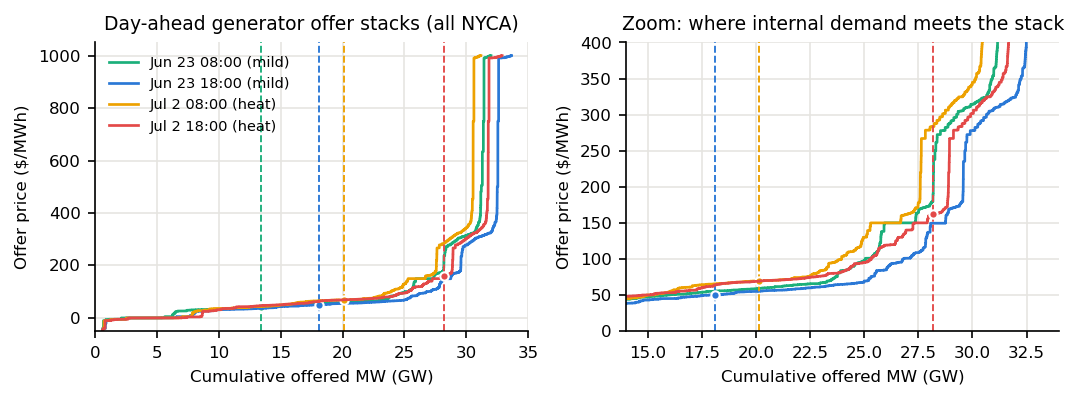

In [15]:
# --- Figure 5: load, forecast, oil, prices ---
x = np.arange(len(h))
fig, ax = plt.subplots(2, 1, figsize=(7.2, 3.3), sharex=True, gridspec_kw={'height_ratios': [1, 1.4]})
a = ax[0]
a.plot(x, h.Load / 1e3, color=COLORS[0], label='Actual load')
a.plot(x, h.LF_DA / 1e3, color=COLORS[1], ls='--', lw=1, label='Day-ahead forecast')
a.fill_between(x, 0, h['F_Other Fossil Fuels'] / 1e3, color=COLORS[4], lw=0, label='Oil-fired gen (Other Fossil)')
a.set(ylabel='GW', ylim=(0, 34), title='NYISO load, forecast and prices: mild week vs heat week')
a.legend(ncol=3, loc='upper left')
a = ax[1]
a.plot(x, h.DA_NYC, color=COLORS[7], lw=1.2, label='DA N.Y.C.'); a.plot(x, h.RT_NYC, color=COLORS[7], lw=0.8, ls=':', label='RT N.Y.C.')
a.plot(x, h.DA_WEST, color=COLORS[0], lw=1.2, label='DA West'); a.plot(x, h.RT_WEST, color=COLORS[0], lw=0.8, ls=':', label='RT West')
a.set_yscale('symlog', linthresh=100)
a.set_yticks([0, 50, 100, 300, 1000, 2000]); a.set_yticklabels(['0', '50', '100', '300', '1000', '2000'])
a.set(ylabel='$/MWh (log scale above 100)', ylim=(-10, 3000)); a.legend(ncol=4, loc='upper left')
for a in ax: a.axvline(119.5, color='#9a9994', lw=0.8)
days = h.index.normalize().unique()
a.set_xticks([24 * i + 12 for i in range(len(days))]); a.set_xticklabels(days.strftime('%m/%d'))
plt.tight_layout(); plt.savefig('q6_ts.png')

# --- Figure 6: bid stacks ---
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.7))
for when, (s, demand, lab, col) in stacks.items():
    for a in ax:
        a.step(s.cum_mw / 1e3, s.price, where='post', color=col, lw=1.3, label=lab if a is ax[0] else None)
        a.axvline(demand / 1e3, color=col, ls='--', lw=0.9)
        a.plot(demand / 1e3, clearing_price(s, demand), 'o', color=col, ms=4, mec='white')
ax[0].set(ylim=(-50, 1050), xlim=(0, 35), title='Day-ahead generator offer stacks (all NYCA)')
ax[1].set(ylim=(0, 400), xlim=(14, 34), title='Zoom: where internal demand meets the stack')
for a in ax: a.set(xlabel='Cumulative offered MW (GW)', ylabel='Offer price ($/MWh)')
ax[0].legend(loc='upper left')
plt.tight_layout(); plt.savefig('q6_stacks.png')